<a href="https://colab.research.google.com/github/nikepb01/ComputerVision_Colab/blob/main/4%EA%B0%95_%EC%8B%A4%EC%8A%B5_%ED%9E%88%EC%8A%A4%ED%86%A0%EA%B7%B8%EB%9E%A8%EA%B3%BC_%EC%9D%B4%EB%AF%B8%EC%A7%80%EC%9D%98_%EA%B8%B0%ED%95%98%ED%95%99%EC%A0%81_%EB%B3%80%ED%99%98.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


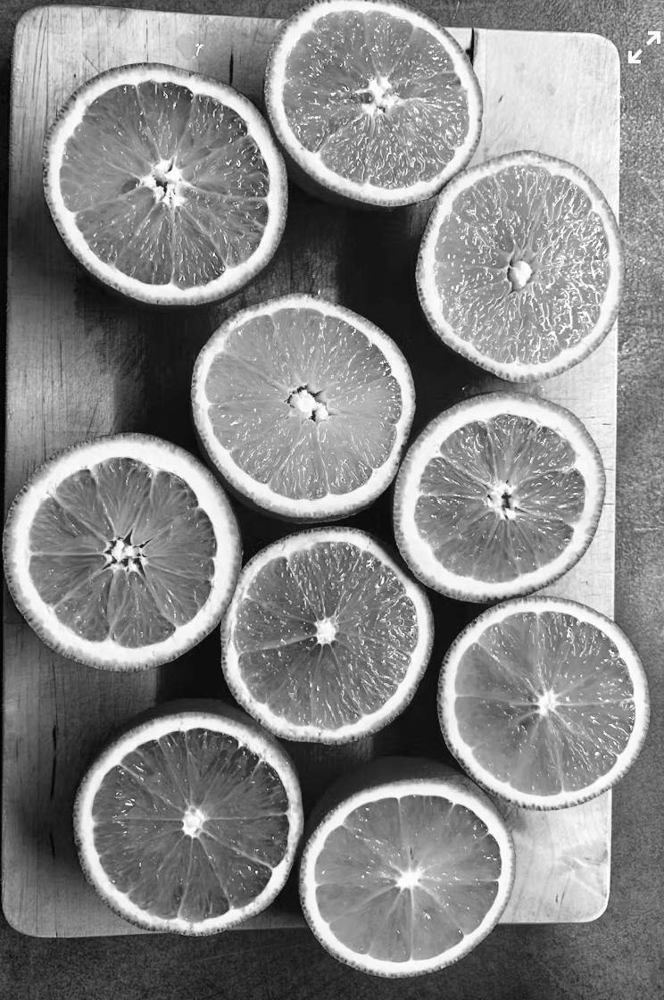

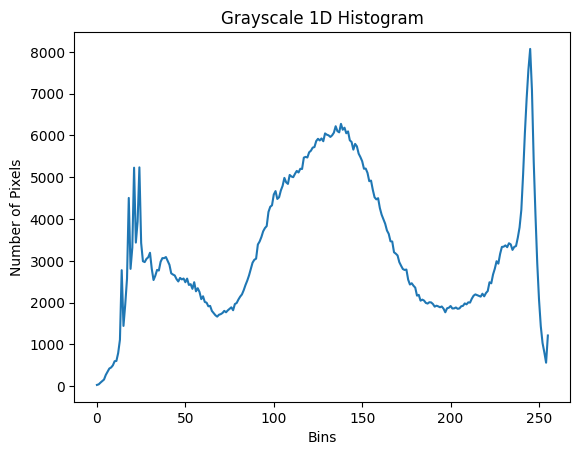

image.shape: (1120, 744)
hist.shape: (256,)
hist.sum(): 833280.0
hist.max(): 8070.0  hist.min(): 30.0


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pylab as plt

grayImage = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/오렌지 사진.jpg', cv2.IMREAD_GRAYSCALE)
cv2_imshow(grayImage)

#히스토그램 계산 및 그리기
#cv2.calcHist(images, chennels, mask, histSize, ranges)
hist = cv2.calcHist([grayImage], [0], None, [256], [0,256])

plt.title("Grayscale 1D Histogram")
plt.xlabel("Bins")
plt.ylabel("Number of Pixels")
plt.plot(hist)
plt.show()


#이미지와 히스토그램의 shape
print("image.shape:",grayImage.shape)
print("hist.shape:", hist.shape)
#히스토그램의 총 픽셀 수(합계)와 하나의 빈에 포함된 최소/최대 픽셀 갯수
print("hist.sum():", hist.sum())
print("hist.max():",hist.max()," hist.min():",hist.min())

=========grayImage=========
image.shape: (1117, 2047)
hist.shape: (256,) hist.sum(): 2286499.0
=========maskedImage=========
image.shape: (1117, 2047)
hist.shape: (256,) hist.sum(): 24000.0


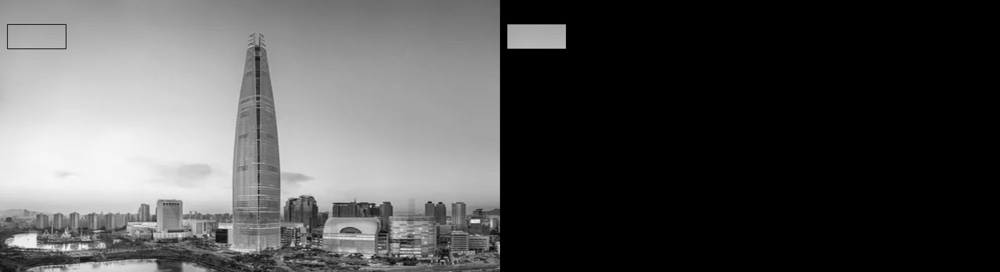

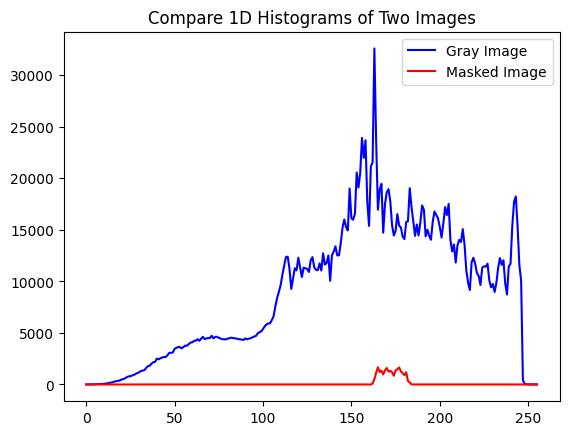

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

image_path = '/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/롯데타워_동일크기.jpg'
grayImage = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if grayImage is None:
    raise FileNotFoundError(f'이미지를 읽지 못했습니다. 경로를 확인하세요: {image_path}')

# 마스킹할 ROI 위치
x, y, w, h = 30, 100, 240, 100

# 마스크 생성
mask = np.zeros(grayImage.shape[:2], dtype=np.uint8)
mask[y:y+h, x:x+w] = 255
maskedImage = cv2.bitwise_and(grayImage, grayImage, mask=mask)

# 히스토그램 계산
grayImageHist = cv2.calcHist([grayImage], [0], None, [256], [0, 256])
maskedHist = cv2.calcHist([grayImage], [0], mask, [256], [0, 256])

print("=========grayImage=========")
print("image.shape:", grayImage.shape)
print("hist.shape:", grayImageHist.shape, "hist.sum():", grayImageHist.sum())

print("=========maskedImage=========")
print("image.shape:", maskedImage.shape)
print("hist.shape:", maskedHist.shape, "hist.sum():", maskedHist.sum())

# 원본은 복사해서 표시: 히스토그램을 계산한 이미지 자체는 수정하지 않음
displayImage = grayImage.copy()
cv2.rectangle(displayImage, (x, y), (x+w, y+h), 0, 2)

cv2_imshow(cv2.hconcat([displayImage, maskedImage]))

plt.title("Compare 1D Histograms of Two Images")
plt.plot(grayImageHist, color='b', label='Gray Image')
plt.plot(maskedHist, color='r', label='Masked Image')
plt.legend()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


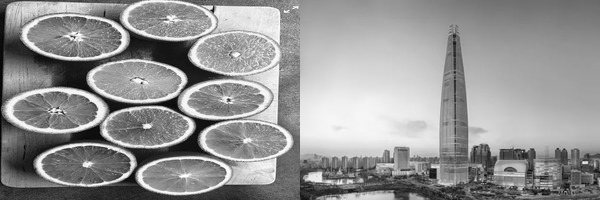

=========Image1=========
image.shape: (200, 300)
hist.shape: (256,)  hist.sum(): 60000.0  hist.max(): 492.0  hist.min(): 4.0
=========Image2=========
image.shape: (200, 300)
hist.shape: (256,)  hist.sum(): 60000.0  hist.max(): 820.0  hist.min(): 0.0




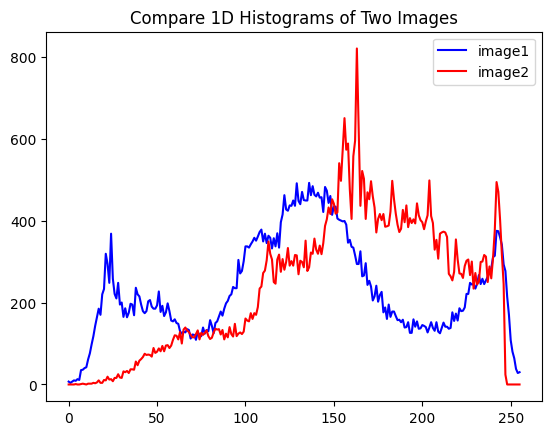

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from google.colab.patches import cv2_imshow

grayImage1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/4강_오렌지 사진.jpg', cv2.IMREAD_GRAYSCALE)
grayImage2 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/4강_롯데타워_동일크기.jpg', cv2.IMREAD_GRAYSCALE)

# Check if images are loaded successfully
if grayImage1 is None:
    print(f"Error: Could not load grayImage1 from '/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/오렌지 사진.jpg'. Check the path.")
    raise FileNotFoundError("Image 1 not found.")
if grayImage2 is None:
    print(f"Error: Could not load grayImage2 from '/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/롯데타워_동일크기.jpg'. Check the path.")
    raise FileNotFoundError("Image 2 not found.")

# Get heights and widths of the images
h1, w1 = grayImage1.shape[:2]
h2, w2 = grayImage2.shape[:2]

# Determine a common height (e.g., the minimum height to avoid upscaling larger image significantly)
common_height = min(h1, h2)

# Resize grayImage1 to the common height, maintaining aspect ratio
aspect_ratio1 = w1 / h1
new_w1 = int(common_height * aspect_ratio1)
resized_grayImage1 = cv2.resize(grayImage1, (new_w1, common_height), interpolation=cv2.INTER_AREA)

# Resize grayImage2 to the common height, maintaining aspect ratio
aspect_ratio2 = w2 / h2
new_w2 = int(common_height * aspect_ratio2)
resized_grayImage2 = cv2.resize(grayImage2, (new_w2, common_height), interpolation=cv2.INTER_AREA)

image_frame = cv2.hconcat([resized_grayImage1, resized_grayImage2])
cv2_imshow(image_frame)

#cv2.calcHist(images, chennels, mask, histSize, ranges)
hist1 = cv2.calcHist([grayImage1],[0],None,[256],[0,256])
hist2 = cv2.calcHist([grayImage2],[0],None,[256],[0,256])

print("=========Image1=========")
print("image.shape:",grayImage1.shape)
print("hist.shape:",hist1.shape," hist.sum():",hist1.sum()," hist.max():",hist1.max()," hist.min():",hist1.min())

print("=========Image2=========")
print("image.shape:",grayImage2.shape)
print("hist.shape:",hist2.shape," hist.sum():",hist2.sum()," hist.max():",hist2.max()," hist.min():",hist2.min())
print("\n")

plt.title("Compare 1D Histograms of Two Images")
plt.plot(hist1,color='b',label='image1')
plt.plot(hist2,color='r',label='image2')

plt.legend()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


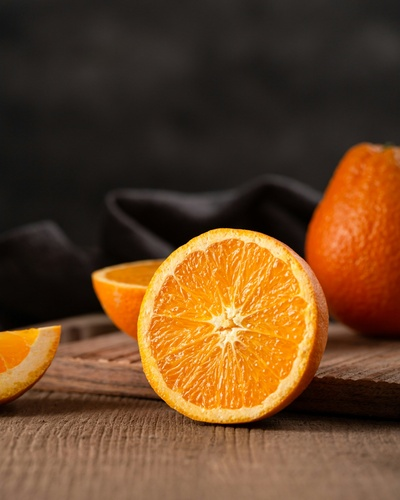

colorImage.shape: (500, 400, 3)
b channel] hist.shape: (256,)  hist.sum(): 200000.0  hist.max(): 12857.0  hist.min(): 0.0
g channel] hist.shape: (256,)  hist.sum(): 200000.0  hist.max(): 4922.0  hist.min(): 0.0
r channel] hist.shape: (256,)  hist.sum(): 200000.0  hist.max(): 6430.0  hist.min(): 66.0


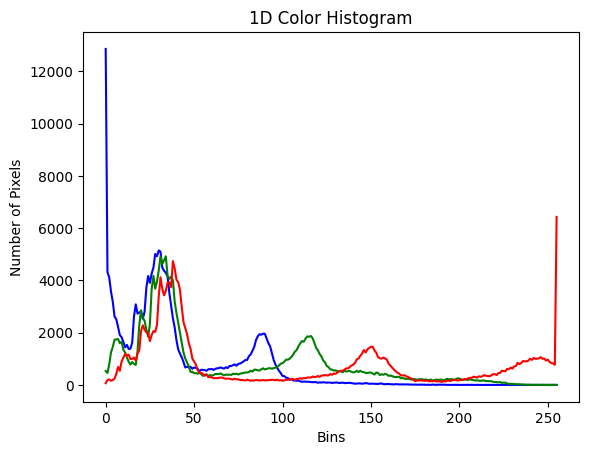

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pylab as plt

colorImage = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/orange-unsplash_400x500.jpg')
cv2_imshow(colorImage)
print("colorImage.shape:",colorImage.shape)

#히스토그램 계산 및 그리기
#b,g,r = cv2.split(colorImage)와 동일
channels = cv2.split(colorImage)
colors = ('b','g','r') #matplotlib 그래프 색상 명시

plt.title("1D Color Histogram")
plt.xlabel("Bins")
plt.ylabel("Number of Pixels")

for (channel, color) in zip (channels, colors):
    #cv2.calcHist(images, chennels, mask, histSize, ranges)
    hist = cv2.calcHist([channel], [0], None, [256], [0, 256])
    plt.plot(hist, color = color)
    print(color,"channel] hist.shape:",hist.shape," hist.sum():",hist.sum()," hist.max():",hist.max()," hist.min():",hist.min())
plt.show()

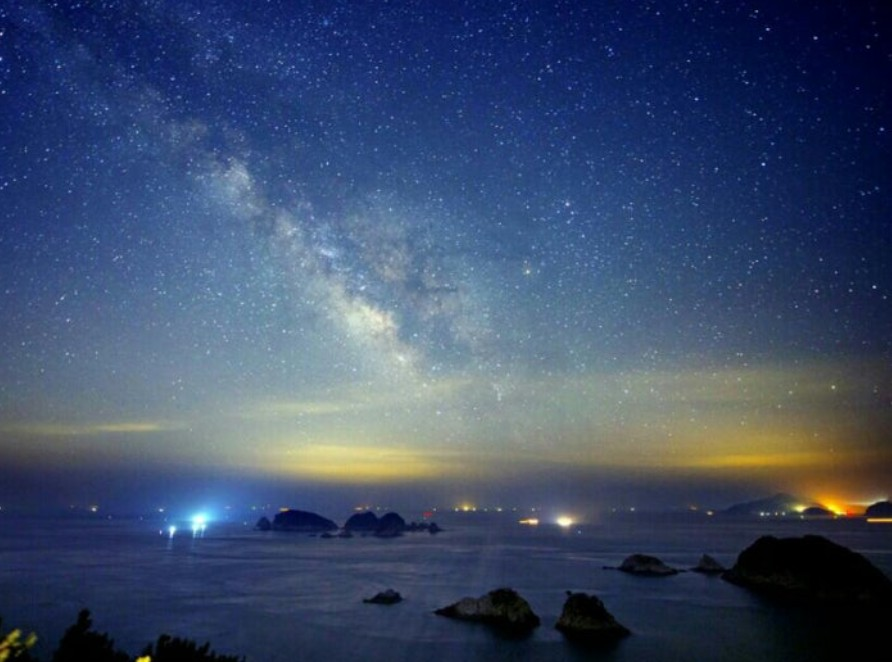

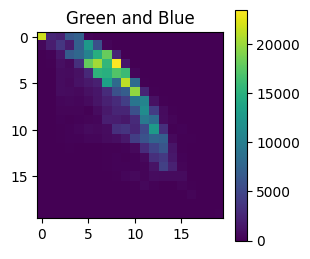

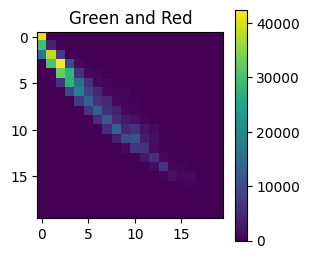

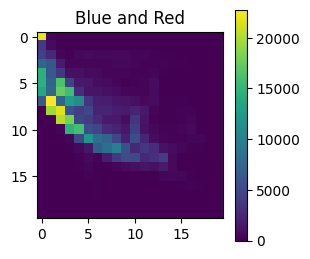

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pylab as plt

colorImage = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/은하수.jpg')
cv2_imshow(colorImage)



#임의로 정한 빈의 갯수
binSize = 20

#픽셀의 초록색과 파란색 값에 따른 분포
plt.figure(figsize=(3,3))
plt.title("Green and Blue")
hist = cv2.calcHist([colorImage], [1, 0], None, [binSize,binSize], [0, 256, 0, 256])
p = plt.imshow(hist, interpolation = "nearest")
plt.colorbar(p)

#픽셀의 초록색과 빨간색 값에 따른 분포
plt.figure(figsize=(3,3))
plt.title("Green and Red")
hist = cv2.calcHist([colorImage], [1, 2], None, [binSize,binSize], [0, 256, 0, 256])
p = plt.imshow(hist, interpolation = "nearest")
plt.colorbar(p)

#픽셀의 파란색과 빨간색 값에 따른 분포
plt.figure(figsize=(3,3))
plt.title("Blue and Red")
hist = cv2.calcHist([colorImage], [0, 2], None, [binSize,binSize], [0, 256, 0, 256])
p = plt.imshow(hist, interpolation = "nearest")
plt.colorbar(p)

plt.show()

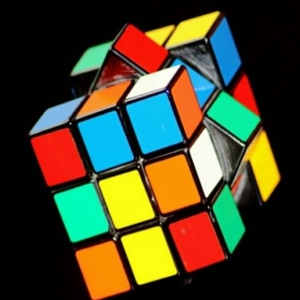

Max: 33775.0 , Min: 0.0
Plot Circle Size Ratio: 0.029607698


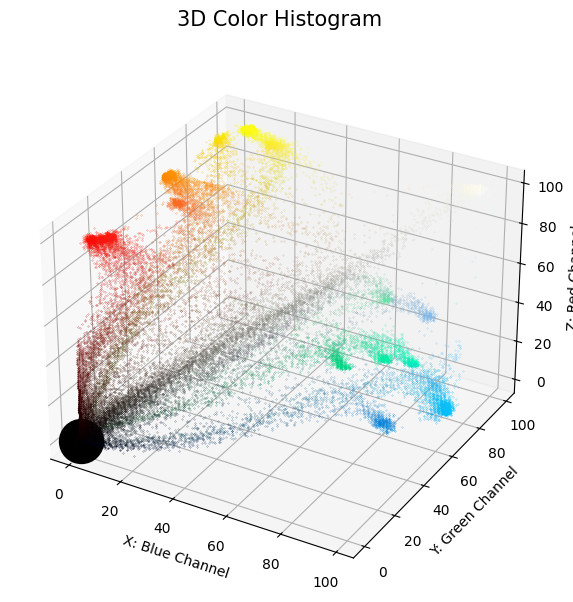

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pylab as plt
#from mpl_toolkits.mplot3d import Axes3D

colorImage = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/큐브_변환.jpg')
cv2_imshow(colorImage)

#임의로 정한 RGB 색상 빈의 갯수
binSize = 100

hist3D = cv2.calcHist([colorImage], [0, 1, 2], None, [binSize, binSize, binSize], [0, 256, 0, 256, 0, 256])
#가장 많은 픽셀을 포함 한 3D히스토그램의 빈의 픽셀 갯수와 최소 픽셀 갯수
print("Max:",np.max(hist3D),", Min:",np.min(hist3D))
#가장 큰 빈을 scatter plot으로 표현할 원의 최대 크기
circleMax = 1000
ratio = circleMax / np.max(hist3D)
print("Plot Circle Size Ratio:",ratio)


fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111,projection="3d")
for (bCount, plane) in enumerate(hist3D):
  for (gCount, row) in enumerate(plane):
    for (rCount, col) in enumerate(row):
      if hist3D[bCount][gCount][rCount] > 0.0:
        size = ratio * hist3D[bCount][gCount][rCount]
        rgb = (rCount/(binSize-1), gCount/(binSize-1), bCount/(binSize-1))
        ax.scatter(bCount, gCount, rCount, s = size, facecolors = rgb)

plt.title("3D Color Histogram",fontsize=15,pad=20,ha='center')
ax.set_xlabel('X: Blue Channel')
ax.set_ylabel('Y: Green Channel')
ax.set_zlabel('Z: Red Channel')
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


=========Original Gray Image=========
Min: 0 Max: 255 Mean: 129.4791
=========OpenCV Normalized Image=========
Min: 0 Max: 255 Mean: 129.4791
=========Manually Normalized Image=========
Min: 0 Max: 255 Mean: 129.4791




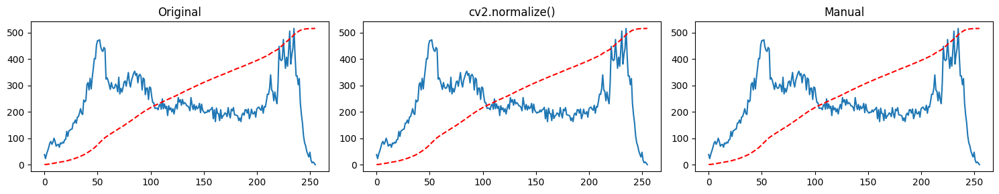

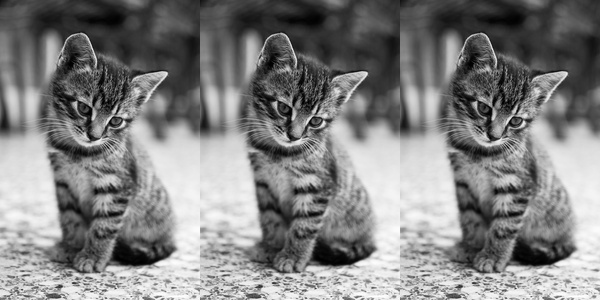

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pylab as plt

grayImage = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/고양이_200x300.jpg',cv2.IMREAD_GRAYSCALE)

print("=========Original Gray Image=========")
print("Min:",grayImage.min(),"Max:",grayImage.max(),"Mean:",grayImage.mean())

#OpenCV를 이용해 연산한 정규화 이미지
cvNormalized = cv2.normalize(grayImage, None, 0, 255, cv2.NORM_MINMAX)
print("=========OpenCV Normalized Image=========")
print("Min:",cvNormalized.min(),"Max:",cvNormalized.max(),"Mean:",cvNormalized.mean())


#직접 연산한 정규화 이미지
image = grayImage.astype(np.float32)
manNormalized = ((image-image.min())/(image.max()-image.min()))*(255)
manNormalized = manNormalized.astype(np.uint8)
print("=========Manually Normalized Image=========")
print("Min:",manNormalized.min(),"Max:",manNormalized.max(),"Mean:",manNormalized.mean())
print("\n")

#각각 히스토그램 계산
#cv2.calcHist(images, chennels, mask, histSize, ranges)
hist = cv2.calcHist([grayImage], [0], None, [256], [0, 255])
cvNormalizedHist = cv2.calcHist([cvNormalized], [0], None, [256], [0, 255])
manNormalizedHist = cv2.calcHist([manNormalized], [0], None, [256], [0, 255])


hists = {'Original': hist,'cv2.normalize()':cvNormalizedHist,'Manual':manNormalizedHist,}

fig=plt.figure(figsize=(15,3))
for i, (title, hist) in enumerate(hists.items()):
    plt.subplot(1,3,i+1)
    plt.title(title)
    plt.plot(hist)
    normalizedCDF = np.cumsum(hist)/hist.sum()*hist.max()
    plt.plot(normalizedCDF,'r--')
plt.tight_layout()
plt.show()


print("\n")
image_frame = cv2.hconcat([grayImage,cvNormalized,manNormalized])
cv2_imshow(image_frame)

CDF Max: 60000.0 CDF Min: 38.0


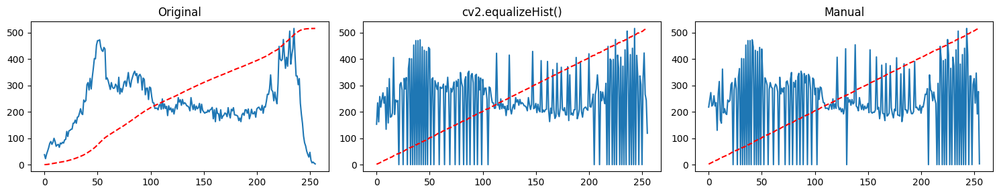

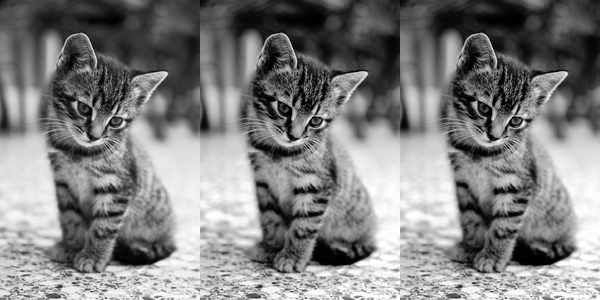

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pylab as plt

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/고양이_200x300.jpg', cv2.IMREAD_GRAYSCALE)


#OpenCV 이퀄라이즈 히스토그램 적용
cvEqImage = cv2.equalizeHist(image)

#원본 이미지 히스토그램 구하기
hist = cv2.calcHist([image], [0], None, [256], [0, 256])  #히스토그램 계산

#누적 히스토그램(Cumulative Distribution Function(CDF))
#hist.cumsum(): cumulative sum of array elements over a given axis)
CDF = hist.cumsum()
#넘파이의 숫자마스크 기능 x의 값이 value의 값과 같으면 NaN으로 마스킹
#ma.masked_equal(x,value)
maskedCDF = np.ma.masked_equal(CDF, 0) #0(zero)인 값을 NaN으로 제거

print("CDF Max:",maskedCDF.max(),"CDF Min:",maskedCDF.min()) #0을 제외한 최소값 출력
maskedCDF = (maskedCDF-maskedCDF.min())/(maskedCDF.max()-maskedCDF.min())*(256-1)   # 이퀄라이즈 히스토그램 계산
CDF = np.ma.filled(maskedCDF,0).astype('uint8') # NaN을 다시 0으로 변환
manEqImage = CDF[image] # 히스토그램을 픽셀로 맵핑


#이퀄라이즈 결과 히스토그램 계산
hist2 = cv2.calcHist([cvEqImage], [0], None, [256], [0, 256])
hist3 = cv2.calcHist([manEqImage], [0], None, [256], [0, 256])

#결과 출력
fig=plt.figure(figsize=(15,3))
hists = {'Original':hist, 'cv2.equalizeHist()':hist2, 'Manual':hist3}
for i, (title, hist) in enumerate(hists.items()):
    plt.subplot(1,3,i+1)
    plt.title(title)
    plt.plot(hist)
    normalizedCDF = np.cumsum(hist)/hist.sum()*hist.max()
    plt.plot(normalizedCDF,'r--')
plt.tight_layout()
plt.show()

print("\n")
image_frame = cv2.hconcat([image,cvEqImage,manEqImage])
cv2_imshow(image_frame)

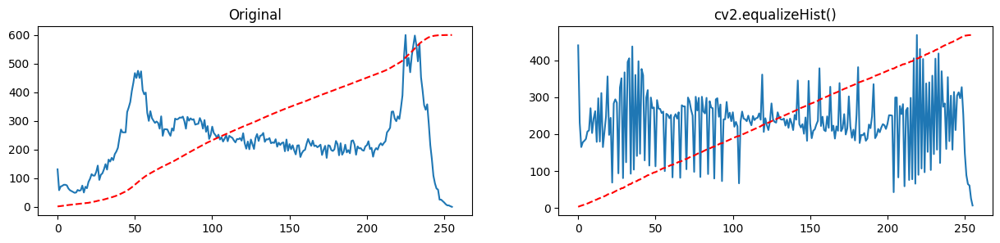

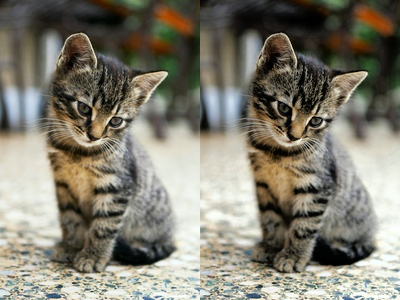

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pylab as plt

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/고양이_200x300.jpg')
hsvImage = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

#HSV 컬러 스페이스 중 Value 체널 대해서 이퀄라이즈 적용
hsvImage[:,:,2] = cv2.equalizeHist(hsvImage[:,:,2])
#컬러 스케일을 HSV에서 BGR로 변경
eqImage = cv2.cvtColor(hsvImage, cv2.COLOR_HSV2BGR)

#이퀄라이즈 결과 히스토그램 계산
hist1 = cv2.calcHist([image], [2], None, [256], [0, 256])
hist2 = cv2.calcHist([eqImage], [2], None, [256], [0, 256])

#결과 출력
hists = {'Original':hist1, 'cv2.equalizeHist()':hist2}
fig=plt.figure(figsize=(15,3))
for i, (title, hist) in enumerate(hists.items()):
    plt.subplot(1,2,i+1)
    plt.title(title)
    plt.plot( hist)
    normalizedCDF = np.cumsum(hist)/hist.sum()*hist.max()
    plt.plot(normalizedCDF,'r--')
plt.show()

print("")
image_frame = cv2.hconcat([image,eqImage])
cv2_imshow(image_frame)

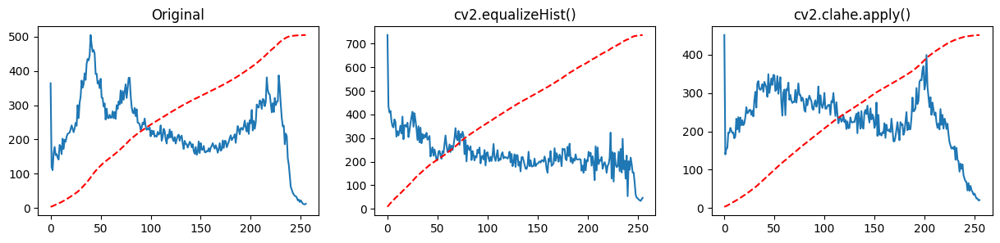

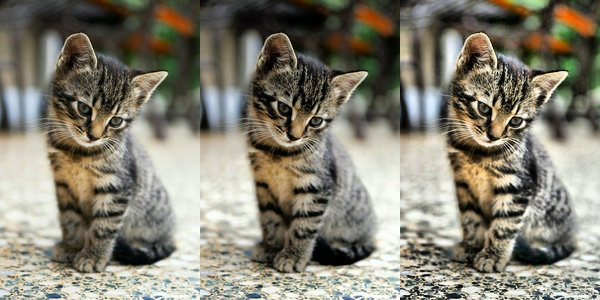

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pylab as plt

#HSV 이미지로 변경
image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/고양이_200x300.jpg')
hsvImage = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

#HSV 컬러 스페이스 중 Value 체널 대해서 이퀄라이즈 적용
eqImage = hsvImage.copy()
eqImage[:,:,2] = cv2.equalizeHist(eqImage[:,:,2])
eqImage = cv2.cvtColor(eqImage, cv2.COLOR_HSV2BGR)

#밝기 채널에 대해서 CLAHE 적용
claheImage = hsvImage.copy()
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))  #CLAHE 생성
claheImage [:,:,2] = clahe.apply(claheImage [:,:,2])        #CLAHE 적용
claheImage  = cv2.cvtColor(claheImage , cv2.COLOR_HSV2BGR)

#히스토그램 계산
hist1 = cv2.calcHist([image], [0], None, [256], [0, 256])
hist2 = cv2.calcHist([eqImage], [0], None, [256], [0, 256])
hist3 = cv2.calcHist([claheImage], [0], None, [256], [0, 256])

#결과 출력
hists = {'Original':hist1,'cv2.equalizeHist()':hist2,'cv2.clahe.apply()':hist3}
fig=plt.figure(figsize=(15,3))
for i, (title,hist) in enumerate(hists.items()):
    plt.subplot(1,3,i+1)
    plt.title(title)
    plt.plot(hist)
    normalizedCDF = np.cumsum(hist)/hist.sum()*hist.max()
    plt.plot(normalizedCDF,'r--')
plt.show()


print("")
image_frame = cv2.hconcat([image,eqImage,claheImage])
cv2_imshow(image_frame)

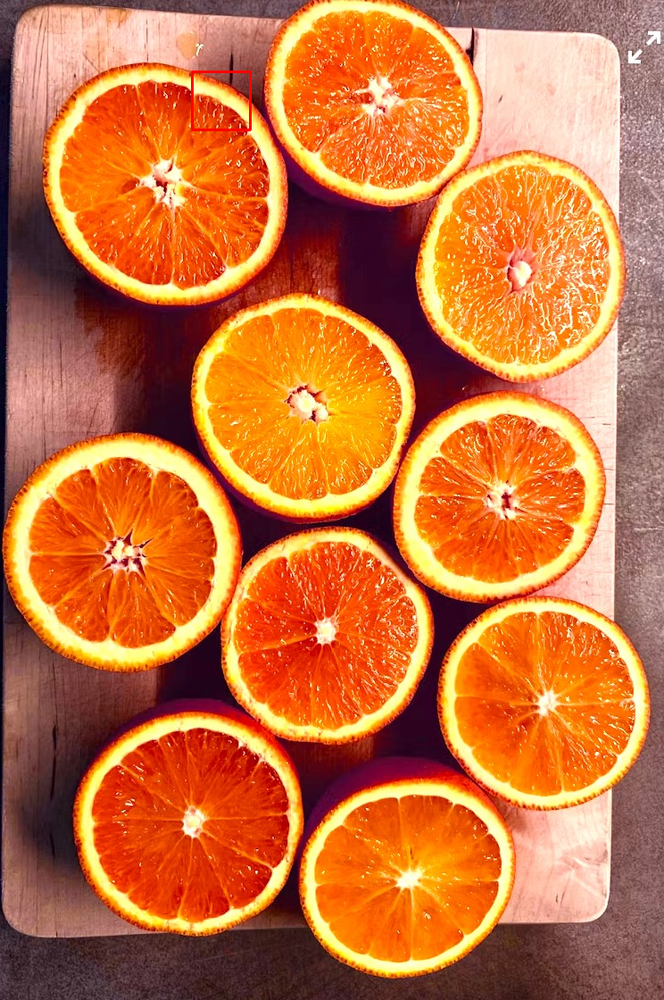

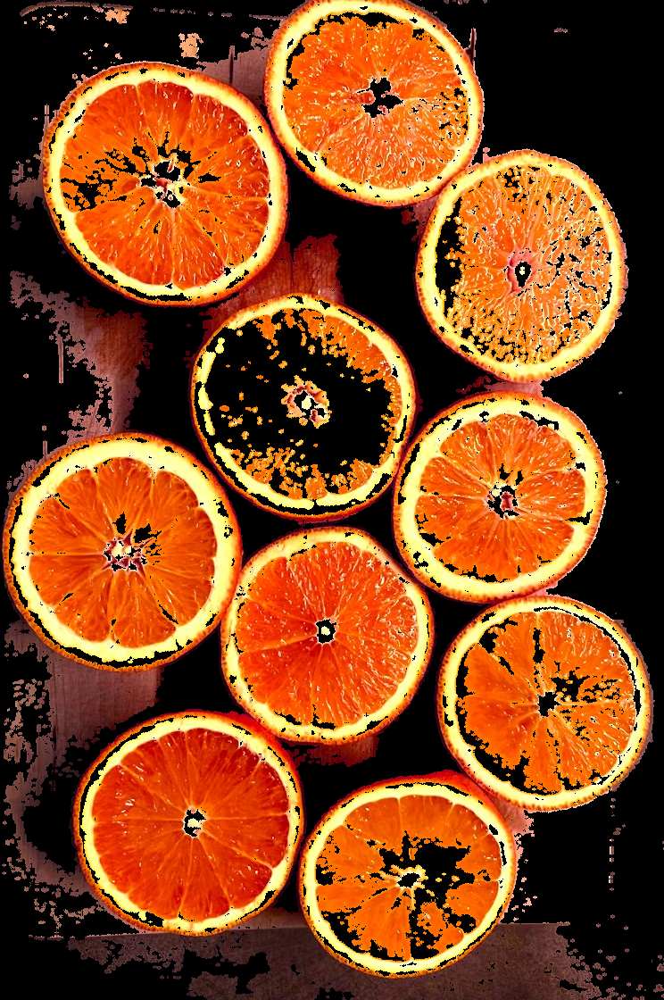

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pylab as plt

image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/오렌지 사진.jpg')
hsvImage = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
draw = image.copy()

# 역투영된 결과를 마스킹해서 결과를 출력하는 함수
def masking(bp):
    disc = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
    cv2.filter2D(bp,-1,disc,bp)
    _, mask = cv2.threshold(bp, 1, 255, cv2.THRESH_BINARY)
    result = cv2.bitwise_and(image, image, mask=mask)
    cv2_imshow(result)

# cv2.calcBackProject() 역투영 함수 사용
def backProject_cv(hist_roi):
    #역투영 함수 호출
    bp = cv2.calcBackProject([hsvImage], [0, 1], hist_roi,  [0, 180, 0, 256], 1)
    #역 투영 결과로 마스킹해서 결과 출력
    masking(bp)

#직접 구현한 역투영 함수
def backProject_manual(hist_roi):
    #전체 영상에 대한 H,S 히스토그램 계산
    hist_img = cv2.calcHist([hsvImage], [0,1], None,[180,256], [0,180,0,256])
    #선택영역과 전체 영상에 대한 히스토그램 그램 비율계산
    hist_rate = hist_roi/ (hist_img + 1)
    #비율에 맞는 픽셀 값 매핑
    h,s,v = cv2.split(hsvImage)
    bp = hist_rate[h.ravel(), s.ravel()]
    #비율은 1을 넘어서는 안되기 때문에 1을 넘는 수는 1을 갖게 함
    bp = np.minimum(bp, 1)
    #1차원 배열을 원래의 shape로 변환
    bp = bp.reshape(hsvImage.shape[:2])
    cv2.normalize(bp,bp, 0, 255, cv2.NORM_MINMAX)
    bp = bp.astype(np.uint8)
    #역 투영 결과로 마스킹해서 결과 출력
    masking(bp)


# ROI 선택 후 히스토그램 역투영 결과로 마스킹
(x,y,w,h) = 215,80,65,65
if w > 0 and h > 0:
    roi = draw[y:y+h, x:x+w]
    # 빨간 사각형으로 ROI 영역 표시
    cv2.rectangle(draw, (x, y), (x+w, y+h), (0,0,255), 2)
    cv2_imshow(draw)
    #선택한 ROI를 HSV 컬러 스페이스로 변경
    hsv_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
    #H,S 채널에 대한 히스토그램 계산
    hist_roi = cv2.calcHist([hsv_roi],[0, 1], None, [180, 256], [0, 180, 0, 256] )
    #ROI의 히스토그램을 매뉴얼 구현함수와 OpenCV 이용하는 함수에 각각 전달
    backProject_cv(hist_roi)
    #backProject_manual(hist_roi)

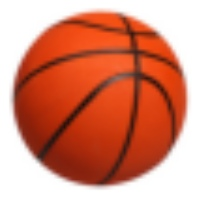

CORREL    	img1:   1.00	img2:   1.00	img3:   0.99	img4:   0.95	img5:   0.98	img6:   0.97	
CHISQR    	img1:   0.00	img2:   0.88	img3:   3.30	img4:   4.28	img5:   2.78	img6:   5.64	
INTERSECT 	img1:   1.00	img2:   0.85	img3:   0.81	img4:   0.31	img5:   0.31	img6:   0.31	
BHATTACHARYYA	img1:   0.00	img2:   0.18	img3:   0.25	img4:   0.73	img5:   0.81	img6:   0.82	


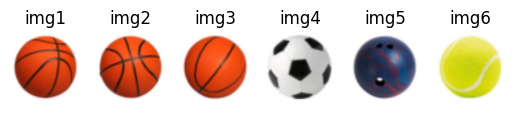

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pylab as plt

img1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/스포츠 공/img1.jpg')
img2 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/스포츠 공/img2.jpg')
img3 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/스포츠 공/img3.jpg')
img4 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/스포츠 공/img4.jpg')
img5 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/스포츠 공/img5.jpg')
img6 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/스포츠 공/img6.jpg')

cv2_imshow(img1)
images = [img1, img2, img3, img4, img5, img6]

hists = []
for i, img in enumerate(images) :
    plt.subplot(1,len(images),i+1)
    plt.title('img%d'% (i+1))
    plt.axis('off')
    plt.imshow(img[:,:,::-1])
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0,1], None, [180,256], [0,180,0, 256])
    cv2.normalize(hist, hist, 0, 1, cv2.NORM_MINMAX)
    hists.append(hist)


query = hists[0]
methods = {'CORREL' :cv2.HISTCMP_CORREL,
           'CHISQR':cv2.HISTCMP_CHISQR,
           'INTERSECT':cv2.HISTCMP_INTERSECT,
           'BHATTACHARYYA':cv2.HISTCMP_BHATTACHARYYA}

for j, (name, flag) in enumerate(methods.items()):
    print('%-10s'%name, end='\t')
    for i, (hist, img) in enumerate(zip(hists, images)):
        #각각의 방법에 따른 image1과 다른 이미지들의 히스토그램 비교분석
        ret = cv2.compareHist(query, hist, flag)
        #교차 분석인 경우 비교대상으로 나누어 1로 정규화
        if flag == cv2.HISTCMP_INTERSECT:
            ret = ret/np.sum(query)
        print("img%d:%7.2f"% (i+1 , ret), end='\t')
    print()
plt.show()